# ReviewIQ – Intelligent Customer Review Analytics System

## 1. Project Overview

ReviewIQ is an NLP and Machine Learning based system designed
to analyse customer reviews and extract meaningful insights.

## 2. Objectives

- Understand customer review data.
- Analyse customer sentiment.
- Identify common customer complaints.
- Discover frequently discussed topics.
- Extract useful business insights.

## 3. Dataset

Women's E-Commerce Clothing Reviews Dataset.

## 4. Technologies

Python, Pandas, NumPy, Matplotlib, Seaborn,
NLTK and Scikit-learn.

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File handling
from pathlib import Path

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Define dataset path
DATA_PATH = Path("../data/raw")

# Find CSV file
csv_files = list(DATA_PATH.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError("No CSV file found in data/raw")

print("Available CSV files:", csv_files)

# Load dataset
df = pd.read_csv(csv_files[0])

print("\nDataset loaded successfully!")

Available CSV files: [WindowsPath('../data/raw/Womens Clothing E-Commerce Reviews.csv')]

Dataset loaded successfully!


In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 23486
Number of Columns: 11


In [4]:
df.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 9.5 MB


In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,23486.0,NaN,NaN,NaN,11742.5,6779.968547,0.0,5871.25,11742.5,17613.75,23485.0
Clothing ID,23486.0,NaN,NaN,NaN,918.118709,203.29898,0.0,861.0,936.0,1078.0,1205.0
Age,23486.0,NaN,NaN,NaN,43.198544,12.279544,18.0,34.0,41.0,52.0,99.0
Title,19676,13993,Love it!,136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review Text,22641,22634,Perfect fit and i've gotten so many compliment...,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,23486.0,NaN,NaN,NaN,4.196032,1.110031,1.0,4.0,5.0,5.0,5.0
Recommended IND,23486.0,NaN,NaN,NaN,0.822362,0.382216,0.0,1.0,1.0,1.0,1.0
Positive Feedback Count,23486.0,NaN,NaN,NaN,2.535936,5.702202,0.0,0.0,1.0,3.0,122.0
Division Name,23472,3,General,13850,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department Name,23472,6,Tops,10468,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Data Quality Investigation

In [7]:
# Calculate missing values
missing_values = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values.sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_values)

,Missing Count,Missing Percentage
Title,3810,16.222430
Review Text,845,3.597888
Department Name,14,0.059610
Class Name,14,0.059610
Division Name,14,0.059610
Unnamed: 0,0,0.000000
Clothing ID,0,0.000000
Age,0,0.000000
Rating,0,0.000000
Recommended IND,0,0.000000


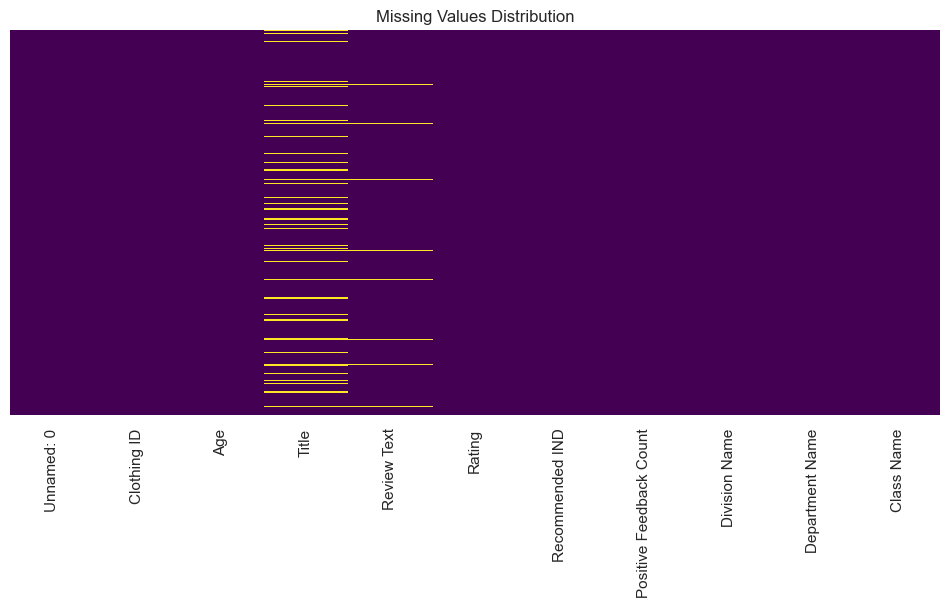

In [8]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title("Missing Values Distribution")
plt.show()

In [9]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


### Data Quality Observations

The dataset was examined to identify missing values and duplicate records.

- Missing values were identified across the dataset using null-value counts and percentages.
- A heatmap was used to visualize the distribution of missing values.
- Duplicate records were checked to understand potential data redundancy.
- These observations help determine the preprocessing steps required before further analysis.

# Rating Distribution

Rating
1      842
2     1565
3     2871
4     5077
5    13131
Name: count, dtype: int64


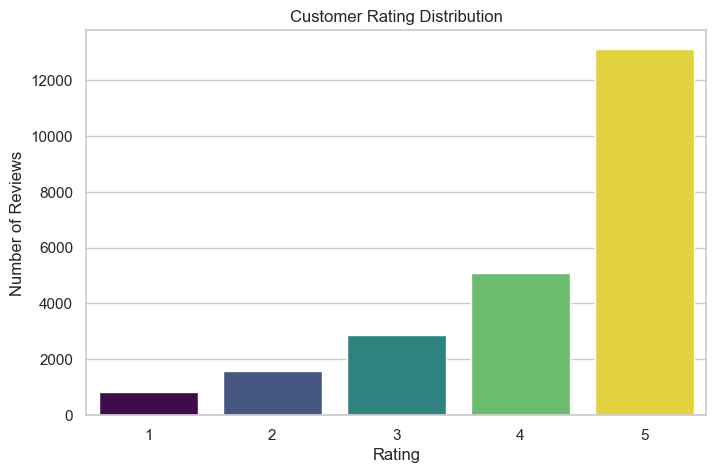

In [10]:
print(df['Rating'].value_counts().sort_index())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Rating',
    hue='Rating',
    palette='viridis',
    legend=False
)

plt.title("Customer Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

### Rating Distribution Observations

The rating distribution shows that customer feedback is heavily concentrated towards higher ratings.

- Rating 5 has the highest number of reviews (13,131).
- Rating 4 is the second most frequent rating (5,077).
- Rating 1 and Rating 2 have comparatively fewer reviews.
- Rating 3 represents the neutral rating category.

This indicates that the dataset has an imbalanced rating distribution, with positive reviews forming the majority. This class imbalance is important to consider during sentiment analysis and model evaluation.

## Categorical Feature Analysis

This section explores the distribution of products across different categorical features:

- **Division Name:** Broad product divisions.
- **Department Name:** Product departments such as Tops, Dresses, and Bottoms.
- **Class Name:** Specific product categories within each department.

These distributions help understand the product categories represented in the dataset.

In [11]:
categorical_columns = [
    'Division Name',
    'Department Name',
    'Class Name'
]

for column in categorical_columns:

    print(f"\n{column} Distribution")

    display(df[column].value_counts())


Division Name Distribution


Division Name
General           13850
General Petite     8120
Initmates          1502
Name: count, dtype: int64


Department Name Distribution


Department Name
Tops        10468
Dresses      6319
Bottoms      3799
Intimate     1735
Jackets      1032
Trend         119
Name: count, dtype: int64


Class Name Distribution


Class Name
Dresses           6319
Knits             4843
Blouses           3097
Sweaters          1428
Pants             1388
Jeans             1147
Fine gauge        1100
Skirts             945
Jackets            704
Lounge             691
Swim               350
Outerwear          328
Shorts             317
Sleep              228
Legwear            165
Intimates          154
Layering           146
Trend              119
Casual bottoms       2
Chemises             1
Name: count, dtype: int64

### Categorical Feature Observations

The categorical feature analysis reveals the following patterns:

- **Division Name:** General has the highest number of reviews (13,850), followed by General Petite (8,120).
- **Department Name:** Tops (10,468) and Dresses (6,319) are the most frequently reviewed departments.
- **Class Name:** Dresses (6,319), Knits (4,843), and Blouses (3,097) are the most represented product classes.
- Some product classes, such as Casual bottoms and Chemises, have very few reviews.

These observations show that the dataset is not uniformly distributed across product categories. This distribution should be considered when interpreting category-level analysis.